In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
import warnings
warnings.filterwarnings('ignore')

print("All libraries imported successfully!")
print("Required packages:")
print("- numpy:", np.__version__)
print("- pandas:", pd.__version__)
print("- matplotlib:", plt.matplotlib.__version__)
print("- PIL (Pillow):", Image.__version__)
print("- seaborn:", sns.__version__)

All libraries imported successfully!
Required packages:
- numpy: 2.1.3
- pandas: 2.2.3
- matplotlib: 3.10.0
- PIL (Pillow): 11.1.0
- seaborn: 0.13.2


In [3]:
data_dir = r"C:\Users\student.CINTEL\Downloads\archive (2)\chest_xray"

if not os.path.exists(data_dir):
    print(f"❌ ERROR: Dataset not found at: {data_dir}")
    print("\n📋 Please:")
    print("1. Download the dataset from: https://www.kaggle.com/datasets/paultimothymooney/chest-xray-pneumonia")
    print("2. Extract the zip file")
    print("3. Update the 'data_dir' variable above with the correct path")
    print("\n📁 Expected folder structure:")
    print("chest_xray/")
    print("  ├── train/")
    print("  │   ├── NORMAL/")
    print("  │   └── PNEUMONIA/")
    print("  ├── test/")
    print("  │   ├── NORMAL/")
    print("  │   └── PNEUMONIA/")
    print("  └── val/")
    print("      ├── NORMAL/")
    print("      └── PNEUMONIA/")
else:
    print(f"✅ Dataset found at: {data_dir}")
    # Show folder contents
    for folder in ['train', 'test', 'val']:
        folder_path = os.path.join(data_dir, folder)
        if os.path.exists(folder_path):
            print(f"📂 {folder}/ folder exists")
            for class_folder in ['NORMAL', 'PNEUMONIA']:
                class_path = os.path.join(folder_path, class_folder)
                if os.path.exists(class_path):
                    count = len([f for f in os.listdir(class_path) 
                               if f.lower().endswith(('.png', '.jpg', '.jpeg'))])
                    print(f"    └── {class_folder}: {count} images")

✅ Dataset found at: C:\Users\student.CINTEL\Downloads\archive (2)\chest_xray
📂 train/ folder exists
    └── NORMAL: 1341 images
    └── PNEUMONIA: 3875 images
📂 test/ folder exists
    └── NORMAL: 234 images
    └── PNEUMONIA: 390 images
📂 val/ folder exists
    └── NORMAL: 8 images
    └── PNEUMONIA: 8 images


In [4]:
class ChestXRayClassifier:
    def __init__(self, img_size=(64, 64)):
        """
        Initialize the classifier
        Args:
            img_size: Tuple for resizing images (width, height)
        """
        self.img_size = img_size
        self.w = None
        self.b = None
        self.mean = None
        self.std = None
        print(f"🏥 ChestXRayClassifier initialized with image size: {img_size}")
        
    def load_and_preprocess_images(self, data_dir):
        """
        Load images from directory structure and convert to numerical features
        """
        X, y = [], []
        labels = {'NORMAL': 0, 'PNEUMONIA': 1}
        
        print("🔄 Loading and preprocessing images...")
        
        # Include validation folder as well
        for split in ['train', 'test', 'val']:
            split_path = os.path.join(data_dir, split)
            if not os.path.exists(split_path):
                print(f"⚠️  Warning: {split_path} not found, skipping...")
                continue
                
            print(f"📁 Processing {split} folder...")
            for label in ['NORMAL', 'PNEUMONIA']:
                label_path = os.path.join(split_path, label)
                if not os.path.exists(label_path):
                    print(f"⚠️  Warning: {label_path} not found, skipping...")
                    continue
                
                image_files = [f for f in os.listdir(label_path) 
                             if f.lower().endswith(('.png', '.jpg', '.jpeg'))]
                print(f"  📊 {label}: {len(image_files)} images")
                
                for i, img_file in enumerate(image_files):
                    img_path = os.path.join(label_path, img_file)
                    try:
                        # Load and preprocess image
                        img = Image.open(img_path).convert('L')  # Convert to grayscale
                        img = img.resize(self.img_size)
                        img_array = np.array(img).flatten()  # Flatten to 1D
                        
                        X.append(img_array)
                        y.append(labels[label])
                        
                        # Progress indicator
                        if (i + 1) % 500 == 0:
                            print(f"    ⏳ Processed {i + 1}/{len(image_files)} images...")
                            
                    except Exception as e:
                        print(f"❌ Error processing {img_path}: {e}")
                        continue
        
        if len(X) == 0:
            raise ValueError("❌ No images were loaded! Please check your dataset path and structure.")
        
        print(f"✅ Successfully loaded {len(X)} images")
        return np.array(X, dtype=np.float32), np.array(y)

In [5]:
class ChestXRayClassifier(ChestXRayClassifier):  # Extend the previous class
    
    def normalize_features(self, X_train, X_test=None):
        """Normalize features using training set statistics"""
        self.mean = X_train.mean()
        self.std = X_train.std() + 1e-8  # Add small epsilon to prevent division by zero
        
        X_train_norm = (X_train - self.mean) / self.std
        print(f"📊 Features normalized - Mean: {self.mean:.2f}, Std: {self.std:.2f}")
        
        if X_test is not None:
            X_test_norm = (X_test - self.mean) / self.std
            return X_train_norm, X_test_norm
        
        return X_train_norm
    
    def sigmoid(self, z):
        """Stable sigmoid function with clipping"""
        z = np.clip(z, -250, 250)  # Prevent overflow
        return 1 / (1 + np.exp(-z))
    
    def train(self, X, y, lr=0.001, epochs=100, batch_size=32, validation_split=0.2):
        """
        Train logistic regression with mini-batch gradient descent
        """
        print(f"🚀 Starting training with lr={lr}, epochs={epochs}, batch_size={batch_size}")
        
        # Split into train/validation
        if validation_split > 0:
            X_train, X_val, y_train, y_val = train_test_split(
                X, y, test_size=validation_split, random_state=42, stratify=y
            )
            print(f"📊 Train samples: {len(X_train)}, Validation samples: {len(X_val)}")
        else:
            X_train, X_val, y_train, y_val = X, None, y, None
            print(f"📊 Train samples: {len(X_train)}")
        
        # Initialize weights
        self.w = np.random.normal(0, 0.01, X_train.shape[1])  # Smaller initialization
        self.b = 0.0
        
        train_losses, val_losses = [], []
        train_accs, val_accs = [], []
        
        n_batches = len(X_train) // batch_size + (1 if len(X_train) % batch_size else 0)
        
        for epoch in range(epochs):
            # Shuffle training data
            indices = np.random.permutation(len(X_train))
            X_shuffled, y_shuffled = X_train[indices], y_train[indices]
            
            epoch_loss = 0
            epoch_correct = 0
            
            # Mini-batch training
            for i in range(0, len(X_train), batch_size):
                X_batch = X_shuffled[i:i+batch_size]
                y_batch = y_shuffled[i:i+batch_size]
                
                # Forward pass
                z = X_batch @ self.w + self.b
                predictions = self.sigmoid(z)
                
                # Binary cross-entropy loss
                loss = -np.mean(y_batch * np.log(predictions + 1e-8) + 
                               (1 - y_batch) * np.log(1 - predictions + 1e-8))
                epoch_loss += loss
                
                # Accuracy for this batch
                batch_pred_labels = (predictions > 0.5).astype(int)
                epoch_correct += np.sum(batch_pred_labels == y_batch)
                
                # Backward pass
                error = predictions - y_batch
                dw = X_batch.T @ error / len(X_batch)
                db = np.mean(error)
                
                # Update weights with L2 regularization
                l2_reg = 0.001
                self.w -= lr * (dw + l2_reg * self.w)
                self.b -= lr * db
            
            # Record training metrics
            avg_loss = epoch_loss / n_batches
            train_accuracy = epoch_correct / len(X_train)
            train_losses.append(avg_loss)
            train_accs.append(train_accuracy)
            
            # Validation metrics
            if X_val is not None:
                val_pred = self.predict_proba(X_val)
                val_loss = -np.mean(y_val * np.log(val_pred + 1e-8) + 
                                   (1 - y_val) * np.log(1 - val_pred + 1e-8))
                val_accuracy = np.mean((val_pred > 0.5) == y_val)
                val_losses.append(val_loss)
                val_accs.append(val_accuracy)
            
            # Print progress
            if epoch % 20 == 0 or epoch == epochs - 1:
                if X_val is not None:
                    print(f"🔄 Epoch {epoch:3d}: Train Loss={avg_loss:.4f}, Train Acc={train_accuracy:.3f}, "
                          f"Val Loss={val_loss:.4f}, Val Acc={val_accuracy:.3f}")
                else:
                    print(f"🔄 Epoch {epoch:3d}: Loss={avg_loss:.4f}, Accuracy={train_accuracy:.3f}")
        
        print("✅ Training completed!")
        return {
            'train_losses': train_losses,
            'val_losses': val_losses,
            'train_accs': train_accs,
            'val_accs': val_accs
        }

In [6]:
class ChestXRayClassifier(ChestXRayClassifier):  # Extend the previous class
    
    def predict_proba(self, X):
        """Predict probabilities"""
        if self.w is None:
            raise ValueError("❌ Model not trained yet!")
        z = X @ self.w + self.b
        return self.sigmoid(z)
    
    def predict(self, X):
        """Make predictions"""
        return (self.predict_proba(X) > 0.5).astype(int)
    
    def evaluate(self, X, y):
        """Evaluate model performance"""
        predictions = self.predict(X)
        probabilities = self.predict_proba(X)
        
        accuracy = np.mean(predictions == y)
        
        # Additional metrics
        tp = np.sum((predictions == 1) & (y == 1))
        fp = np.sum((predictions == 1) & (y == 0))
        tn = np.sum((predictions == 0) & (y == 0))
        fn = np.sum((predictions == 0) & (y == 1))
        
        precision = tp / (tp + fp) if (tp + fp) > 0 else 0
        recall = tp / (tp + fn) if (tp + fn) > 0 else 0
        f1 = 2 * (precision * recall) / (precision + recall) if (precision + recall) > 0 else 0
        
        return {
            'accuracy': accuracy,
            'precision': precision,
            'recall': recall,
            'f1_score': f1,
            'confusion_matrix': np.array([[tn, fp], [fn, tp]]),
            'predictions': predictions,
            'probabilities': probabilities
        }


In [7]:
classifier = ChestXRayClassifier(img_size=(64, 64))

# Load and preprocess data
print("🔄 Starting data loading process...")
X, y = classifier.load_and_preprocess_images(data_dir)

print(f"\n📊 Dataset Summary:")
print(f"Total images loaded: {len(X)}")
print(f"Image dimensions after flattening: {X.shape[1]} pixels ({classifier.img_size[0]}x{classifier.img_size[1]})")
print(f"Normal cases: {np.sum(y == 0)} ({np.sum(y == 0)/len(y)*100:.1f}%)")
print(f"Pneumonia cases: {np.sum(y == 1)} ({np.sum(y == 1)/len(y)*100:.1f}%)")


🏥 ChestXRayClassifier initialized with image size: (64, 64)
🔄 Starting data loading process...
🔄 Loading and preprocessing images...
📁 Processing train folder...
  📊 NORMAL: 1341 images
    ⏳ Processed 500/1341 images...
    ⏳ Processed 1000/1341 images...
  📊 PNEUMONIA: 3875 images
    ⏳ Processed 500/3875 images...
    ⏳ Processed 1000/3875 images...
    ⏳ Processed 1500/3875 images...
    ⏳ Processed 2000/3875 images...
    ⏳ Processed 2500/3875 images...
    ⏳ Processed 3000/3875 images...
    ⏳ Processed 3500/3875 images...
📁 Processing test folder...
  📊 NORMAL: 234 images
  📊 PNEUMONIA: 390 images
📁 Processing val folder...
  📊 NORMAL: 8 images
  📊 PNEUMONIA: 8 images
✅ Successfully loaded 5856 images

📊 Dataset Summary:
Total images loaded: 5856
Image dimensions after flattening: 4096 pixels (64x64)
Normal cases: 1583 (27.0%)
Pneumonia cases: 4273 (73.0%)


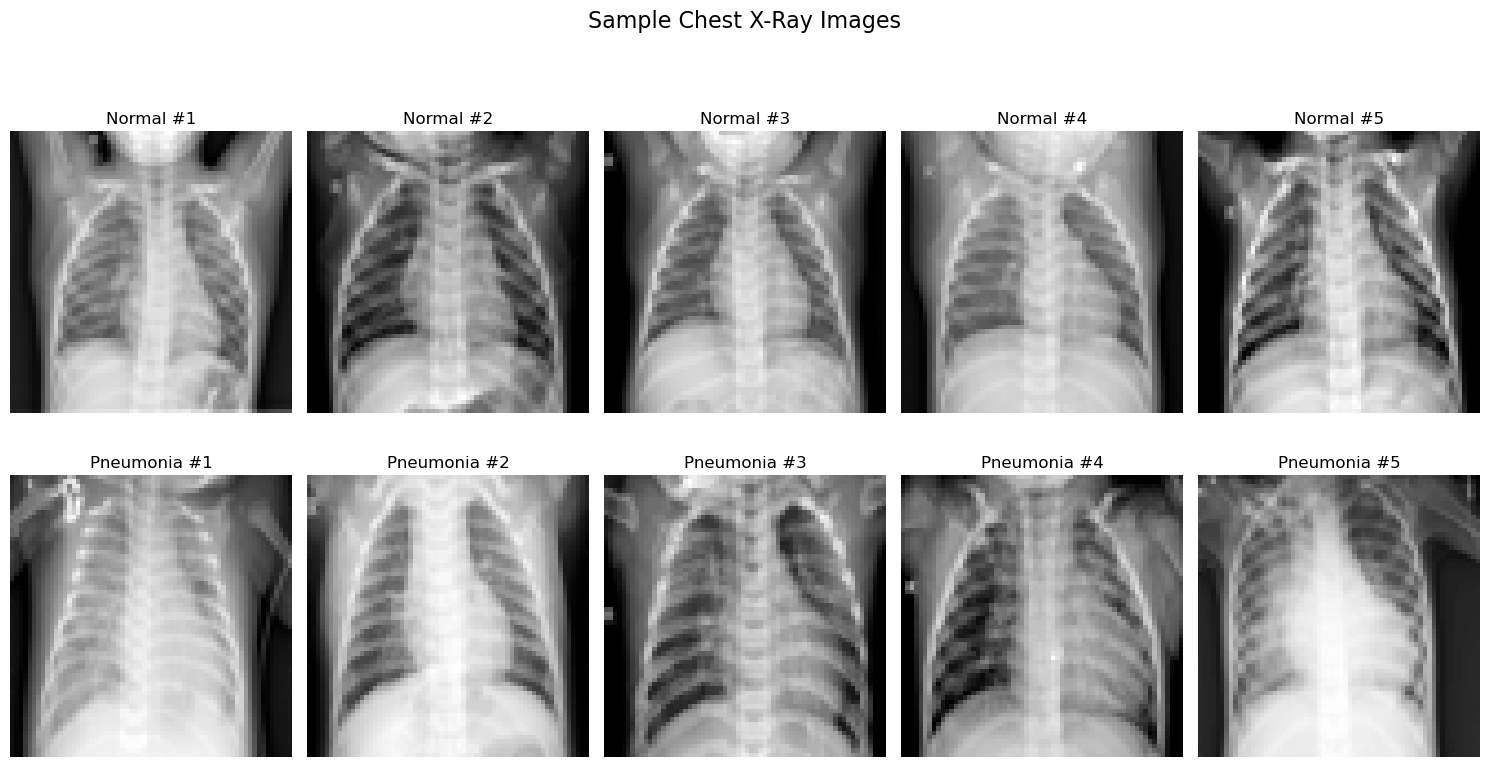

In [8]:
plt.figure(figsize=(15, 8))

# Sample indices for each class
normal_indices = np.where(y == 0)[0]
pneumonia_indices = np.where(y == 1)[0]

# Plot 5 normal and 5 pneumonia samples
for i in range(5):
    # Normal images
    plt.subplot(2, 5, i + 1)
    img_data = X[normal_indices[i]].reshape(classifier.img_size)
    plt.imshow(img_data, cmap='gray')
    plt.title(f'Normal #{i+1}')
    plt.axis('off')
    
    # Pneumonia images  
    plt.subplot(2, 5, i + 6)
    img_data = X[pneumonia_indices[i]].reshape(classifier.img_size)
    plt.imshow(img_data, cmap='gray')
    plt.title(f'Pneumonia #{i+1}')
    plt.axis('off')

plt.suptitle('Sample Chest X-Ray Images', fontsize=16, y=1.02)
plt.tight_layout()
plt.show()

In [9]:
print("🔄 Splitting data into train/test sets...")

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"📊 Data split summary:")
print(f"Training set: {len(X_train)} samples")
print(f"  - Normal: {np.sum(y_train == 0)} ({np.sum(y_train == 0)/len(y_train)*100:.1f}%)")
print(f"  - Pneumonia: {np.sum(y_train == 1)} ({np.sum(y_train == 1)/len(y_train)*100:.1f}%)")
print(f"Test set: {len(X_test)} samples")
print(f"  - Normal: {np.sum(y_test == 0)} ({np.sum(y_test == 0)/len(y_test)*100:.1f}%)")
print(f"  - Pneumonia: {np.sum(y_test == 1)} ({np.sum(y_test == 1)/len(y_test)*100:.1f}%)")

# Normalize features
print("\n🔄 Normalizing features...")
X_train_norm, X_test_norm = classifier.normalize_features(X_train, X_test)

print("✅ Data preprocessing completed!")

🔄 Splitting data into train/test sets...
📊 Data split summary:
Training set: 4684 samples
  - Normal: 1266 (27.0%)
  - Pneumonia: 3418 (73.0%)
Test set: 1172 samples
  - Normal: 317 (27.0%)
  - Pneumonia: 855 (73.0%)

🔄 Normalizing features...
📊 Features normalized - Mean: 122.85, Std: 59.82
✅ Data preprocessing completed!


In [10]:
print("🚀 Training the logistic regression model...")

# Train model
history = classifier.train(
    X_train_norm, y_train, 
    lr=0.001, 
    epochs=100, 
    batch_size=32,
    validation_split=0.2
)

print("\n✅ Training completed successfully!")

🚀 Training the logistic regression model...
🚀 Starting training with lr=0.001, epochs=100, batch_size=32
📊 Train samples: 3747, Validation samples: 937
🔄 Epoch   0: Train Loss=0.4123, Train Acc=0.824, Val Loss=0.2979, Val Acc=0.907
🔄 Epoch  20: Train Loss=0.1587, Train Acc=0.940, Val Loss=0.1851, Val Acc=0.931
🔄 Epoch  40: Train Loss=0.1509, Train Acc=0.947, Val Loss=0.1815, Val Acc=0.933
🔄 Epoch  60: Train Loss=0.1348, Train Acc=0.949, Val Loss=0.1924, Val Acc=0.931
🔄 Epoch  80: Train Loss=0.1241, Train Acc=0.956, Val Loss=0.1771, Val Acc=0.932
🔄 Epoch  99: Train Loss=0.1188, Train Acc=0.955, Val Loss=0.1767, Val Acc=0.933
✅ Training completed!

✅ Training completed successfully!


In [11]:
print("🔍 Evaluating model on test set...")

# Evaluate on test set
test_results = classifier.evaluate(X_test_norm, y_test)

print(f"\n📊 Test Set Results:")
print(f"{'='*50}")
print(f"🎯 Accuracy:  {test_results['accuracy']:.3f} ({test_results['accuracy']*100:.1f}%)")
print(f"🎯 Precision: {test_results['precision']:.3f}")
print(f"🎯 Recall:    {test_results['recall']:.3f}")
print(f"🎯 F1-Score:  {test_results['f1_score']:.3f}")
print(f"{'='*50}")

# Detailed classification report
y_pred = test_results['predictions']
print("\n📋 Detailed Classification Report:")
print(classification_report(y_test, y_pred, target_names=['Normal', 'Pneumonia']))

🔍 Evaluating model on test set...

📊 Test Set Results:
🎯 Accuracy:  0.927 (92.7%)
🎯 Precision: 0.948
🎯 Recall:    0.952
🎯 F1-Score:  0.950

📋 Detailed Classification Report:
              precision    recall  f1-score   support

      Normal       0.87      0.86      0.86       317
   Pneumonia       0.95      0.95      0.95       855

    accuracy                           0.93      1172
   macro avg       0.91      0.91      0.91      1172
weighted avg       0.93      0.93      0.93      1172



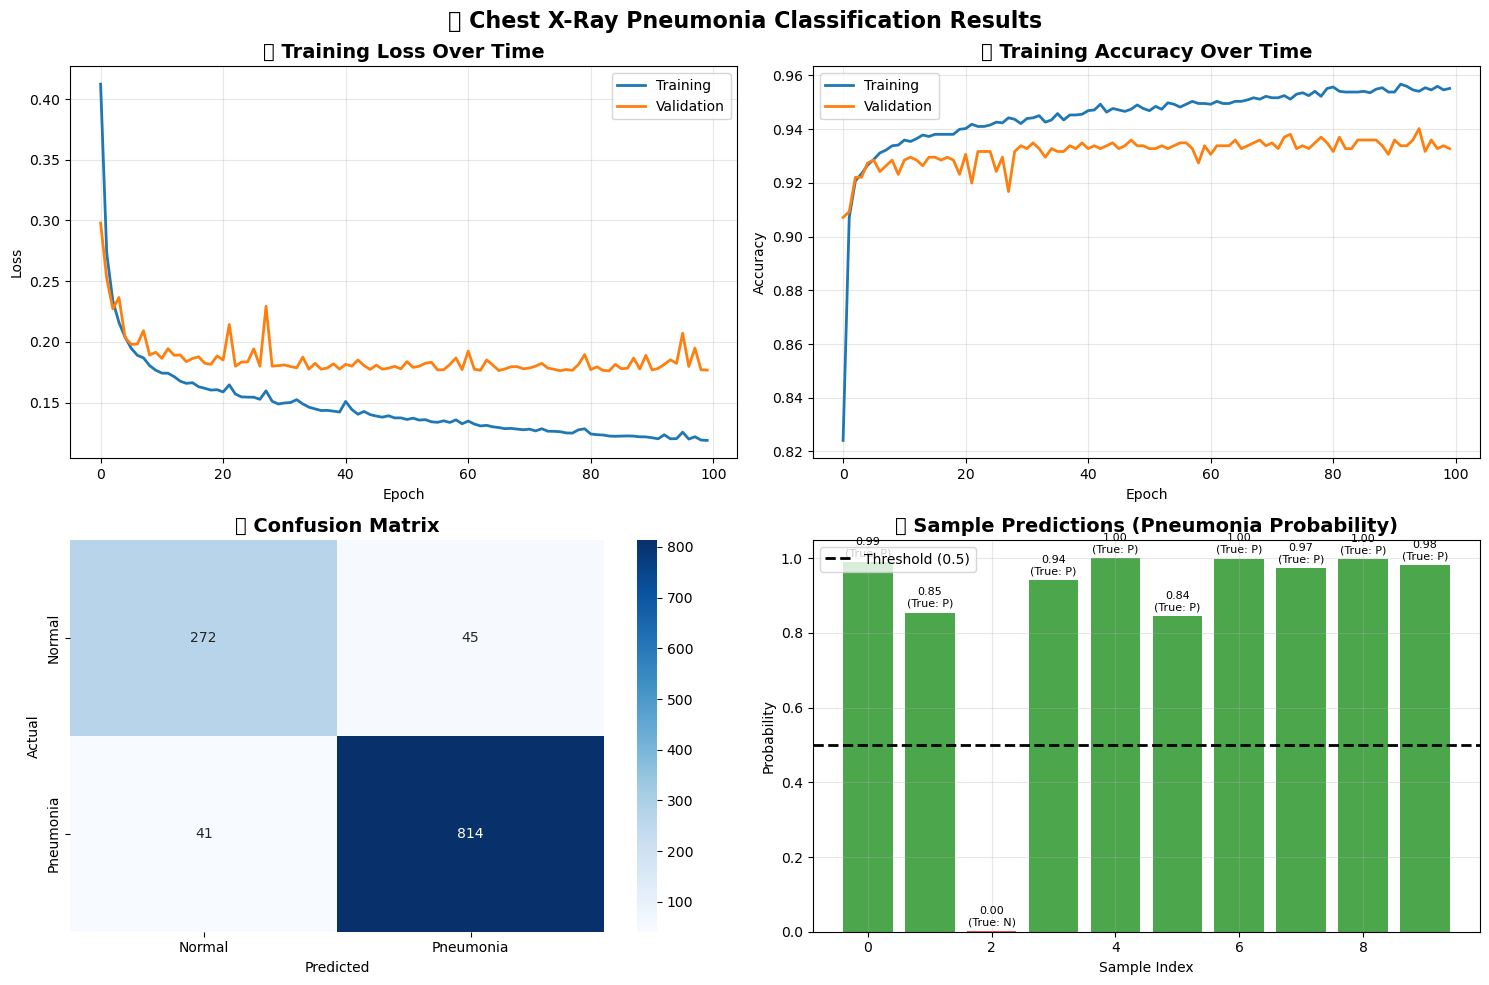

In [12]:
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# Loss plots
axes[0, 0].plot(history['train_losses'], label='Training', linewidth=2)
if history['val_losses']:
    axes[0, 0].plot(history['val_losses'], label='Validation', linewidth=2)
axes[0, 0].set_title('📉 Training Loss Over Time', fontsize=14, fontweight='bold')
axes[0, 0].set_xlabel('Epoch')
axes[0, 0].set_ylabel('Loss')
axes[0, 0].legend()
axes[0, 0].grid(True, alpha=0.3)

# Accuracy plots
axes[0, 1].plot(history['train_accs'], label='Training', linewidth=2)
if history['val_accs']:
    axes[0, 1].plot(history['val_accs'], label='Validation', linewidth=2)
axes[0, 1].set_title('📈 Training Accuracy Over Time', fontsize=14, fontweight='bold')
axes[0, 1].set_xlabel('Epoch')
axes[0, 1].set_ylabel('Accuracy')
axes[0, 1].legend()
axes[0, 1].grid(True, alpha=0.3)

# Confusion matrix
cm = test_results['confusion_matrix']
sns.heatmap(cm, annot=True, fmt='d', ax=axes[1, 0], cmap='Blues',
            xticklabels=['Normal', 'Pneumonia'],
            yticklabels=['Normal', 'Pneumonia'])
axes[1, 0].set_title('🎯 Confusion Matrix', fontsize=14, fontweight='bold')
axes[1, 0].set_xlabel('Predicted')
axes[1, 0].set_ylabel('Actual')

# Sample predictions
sample_indices = np.random.choice(len(X_test), 10, replace=False)
sample_probs = classifier.predict_proba(X_test_norm[sample_indices])
sample_true_labels = y_test[sample_indices]

colors = ['green' if prob > 0.5 else 'red' for prob in sample_probs]
bars = axes[1, 1].bar(range(10), sample_probs, color=colors, alpha=0.7)
axes[1, 1].axhline(y=0.5, color='black', linestyle='--', linewidth=2, label='Threshold (0.5)')
axes[1, 1].set_title('🔮 Sample Predictions (Pneumonia Probability)', fontsize=14, fontweight='bold')
axes[1, 1].set_xlabel('Sample Index')
axes[1, 1].set_ylabel('Probability')
axes[1, 1].legend()
axes[1, 1].grid(True, alpha=0.3)

# Add value labels on bars
for i, (bar, prob, true_label) in enumerate(zip(bars, sample_probs, sample_true_labels)):
    height = bar.get_height()
    axes[1, 1].text(bar.get_x() + bar.get_width()/2., height + 0.01,
                    f'{prob:.2f}\n(True: {"P" if true_label else "N"})',
                    ha='center', va='bottom', fontsize=8)

plt.suptitle('🏥 Chest X-Ray Pneumonia Classification Results', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

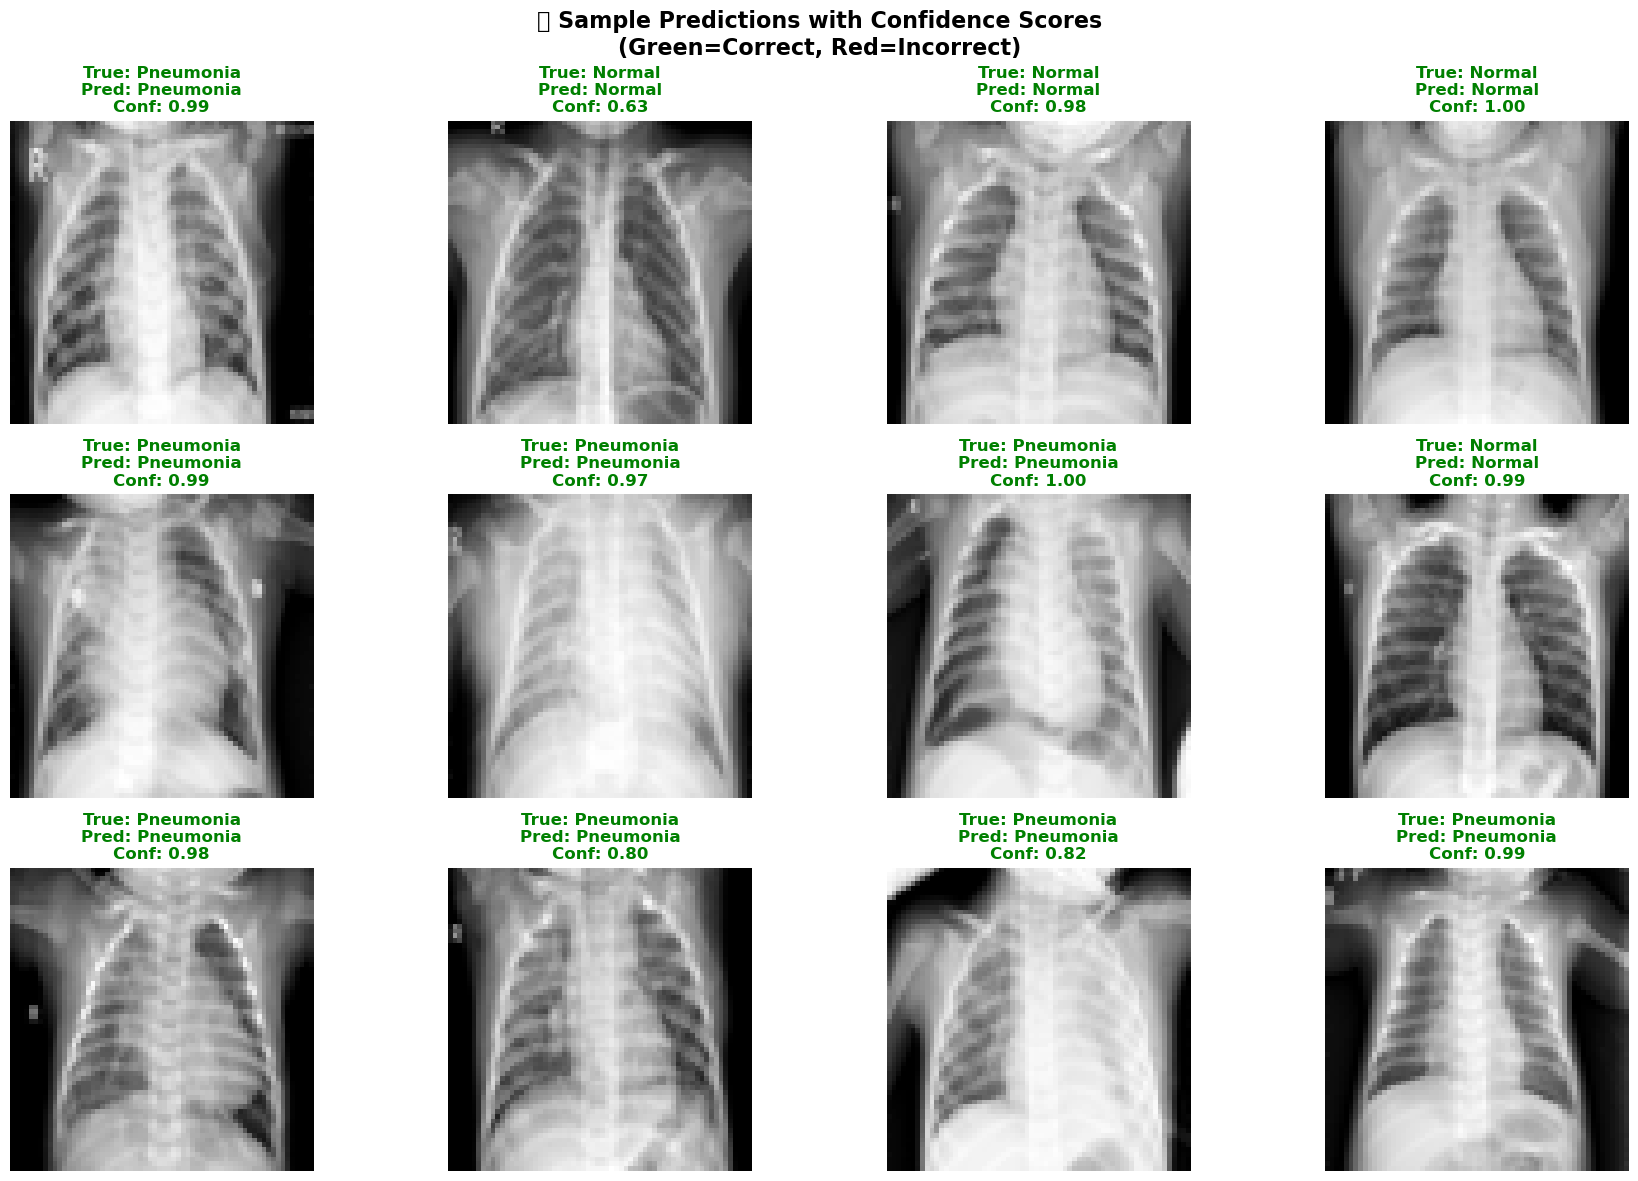

In [13]:
plt.figure(figsize=(18, 12))

# Get some test examples
sample_indices = np.random.choice(len(X_test), 12, replace=False)
sample_images = X_test[sample_indices]
sample_true_labels = y_test[sample_indices] 
sample_predictions = classifier.predict(X_test_norm[sample_indices])
sample_probabilities = classifier.predict_proba(X_test_norm[sample_indices])

for i in range(12):
    plt.subplot(3, 4, i + 1)
    
    # Reshape image back to 2D
    img_data = sample_images[i].reshape(classifier.img_size)
    plt.imshow(img_data, cmap='gray')
    
    # Create title with prediction info
    true_label = "Pneumonia" if sample_true_labels[i] == 1 else "Normal"
    pred_label = "Pneumonia" if sample_predictions[i] == 1 else "Normal"
    confidence = sample_probabilities[i] if sample_predictions[i] == 1 else (1 - sample_probabilities[i])
    
    # Color code: green for correct, red for incorrect
    color = 'green' if sample_predictions[i] == sample_true_labels[i] else 'red'
    
    plt.title(f'True: {true_label}\nPred: {pred_label}\nConf: {confidence:.2f}', 
             color=color, fontweight='bold')
    plt.axis('off')

plt.suptitle('🔍 Sample Predictions with Confidence Scores\n(Green=Correct, Red=Incorrect)', 
             fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

In [14]:
print("📊 FINAL MODEL ANALYSIS")
print("=" * 60)

# Calculate additional statistics
correct_predictions = np.sum(test_results['predictions'] == y_test)
total_predictions = len(y_test)

# False positives and false negatives analysis
fp_indices = np.where((test_results['predictions'] == 1) & (y_test == 0))[0]
fn_indices = np.where((test_results['predictions'] == 0) & (y_test == 1))[0]

print(f"✅ Correct Predictions: {correct_predictions}/{total_predictions} ({correct_predictions/total_predictions*100:.1f}%)")
print(f"❌ False Positives (Normal → Pneumonia): {len(fp_indices)}")
print(f"❌ False Negatives (Pneumonia → Normal): {len(fn_indices)}")

print(f"\n🎯 Model Performance Summary:")
print(f"  • The model achieves {test_results['accuracy']*100:.1f}% accuracy on unseen data")
print(f"  • Precision: {test_results['precision']:.3f} (of predicted pneumonia cases, {test_results['precision']*100:.1f}% are correct)")
print(f"  • Recall: {test_results['recall']:.3f} (model detects {test_results['recall']*100:.1f}% of actual pneumonia cases)")
print(f"  • F1-Score: {test_results['f1_score']:.3f} (balanced measure of precision and recall)")

print(f"\n🏥 Clinical Interpretation:")
if test_results['recall'] > 0.8:
    print(f"  • HIGH SENSITIVITY: Good at detecting pneumonia cases")
else:
    print(f"  • MODERATE SENSITIVITY: May miss some pneumonia cases")
    
if test_results['precision'] > 0.8:
    print(f"  • HIGH PRECISION: Low false alarm rate")
else:
    print(f"  • MODERATE PRECISION: Some false alarms expected")

print(f"\n🔧 Technical Details:")
print(f"  • Image size used: {classifier.img_size}")
print(f"  • Total features: {len(classifier.w):,} pixels")
print(f"  • Training samples: {len(X_train):,}")
print(f"  • Test samples: {len(X_test):,}")

print(f"\n💡 Recommendations for Improvement:")
print(f"  • Use larger image sizes (128x128 or 256x256) for better detail")
print(f"  • Implement Convolutional Neural Networks (CNNs) for better performance")
print(f"  • Apply data augmentation to increase training data")
print(f"  • Consider ensemble methods or deep learning approaches")

📊 FINAL MODEL ANALYSIS
✅ Correct Predictions: 1086/1172 (92.7%)
❌ False Positives (Normal → Pneumonia): 45
❌ False Negatives (Pneumonia → Normal): 41

🎯 Model Performance Summary:
  • The model achieves 92.7% accuracy on unseen data
  • Precision: 0.948 (of predicted pneumonia cases, 94.8% are correct)
  • Recall: 0.952 (model detects 95.2% of actual pneumonia cases)
  • F1-Score: 0.950 (balanced measure of precision and recall)

🏥 Clinical Interpretation:
  • HIGH SENSITIVITY: Good at detecting pneumonia cases
  • HIGH PRECISION: Low false alarm rate

🔧 Technical Details:
  • Image size used: (64, 64)
  • Total features: 4,096 pixels
  • Training samples: 4,684
  • Test samples: 1,172

💡 Recommendations for Improvement:
  • Use larger image sizes (128x128 or 256x256) for better detail
  • Implement Convolutional Neural Networks (CNNs) for better performance
  • Apply data augmentation to increase training data
  • Consider ensemble methods or deep learning approaches
